# P2 results — Reddit hyperlink relationships


We follow three connected questions. First, where does negativity appear in the observed history of a subreddit pair? Second, how does that pair interact after its second observed link? Third, does a subreddit receive more attention from other communities after its first observed negative incoming link? The three analyses use the same cleaned SNAP hyperlink data, but select different events.

A link is negative when `LINK_SENTIMENT = -1`. The `+1` label combines neutral and positive links, so we call it non-negative. Link sentiment describes the recorded post; it does not establish intent, retaliation, or a causal effect.

Notebook outline

- 0. Imports and shared data
  - 0.1 Data checks and preparation
  - 0.2 Baseline: monthly link counts
- 1. Origin: where does negativity first appear? 
  - 1.1 Baseline sentiment by post location (body vs. title)
  - 1.2 Time interval between the first two links in a pair
  - 1.3 Where negativity first appears in a pair history
  - 1.4 Directed origin: unprovoked first strike vs. retaliation
  - 1.5 Location transitions in reciprocal interactions
  - 1.6 Community similarity (subreddit embeddings) and sentiment
- 2. Evolution: how do negative relationships evolve? 
  - 2.1 Select the second observed link in each pair
  - 2.2 Does the other community link back?
    - 2.2.1 Main comparison: the direction of the first link
    - 2.2.2 Overall rates across both direction groups
    - 2.2.3 Pooled time-window sensitivity
    - 2.2.4 Adjustment for prior direction and calendar time
    - 2.2.5 One observed pair, as a timeline
- 3. Wider attention: third-community links 
  - 3.1 Negative events
    - 3.1.1 Incoming links
    - 3.1.2 Time windows and counts
    - 3.1.3 How many negative events can we analyse?
  - 3.2 Matched controls
  - 3.3 The spotlight
    - 3.3.1 Weekly attention around the event
    - 3.3.2 How much more? A ratio of ratios
    - 3.3.3 Is the attention more negative?
  - 3.4 Prior ties and third-party negativity
    - 3.4.1 Detecting temporal triangles
    - 3.4.2 Counting negative temporal triangles
- 4. Synthesis and limits

## 0. Imports and shared data

In [1]:
import pandas as pd
import seaborn as sns

from src.pair_analysis import (
    load_links, prepare_links, show_monthly_baseline,
    show_sentiment_by_location, select_valid_origin_pairs,
    show_response_time_by_sentiment, show_response_time_by_location,
    show_negativity_origin_positions, show_directed_retaliation_origin,
    show_location_transitions, show_location_transitions_by_sentiment_pair,
    add_embedding_similarity, plot_similarity_by_sentiment, fit_similarity_logit,
    select_second_links, measure_pair_responses,
    show_response_by_direction, show_pooled_responses,
    show_window_sensitivity, fit_response_models,
    show_pair_timeline
)
from src.attention import (
    DAY, MIN_LINKS, incoming_links, add_counts,
    select_first_attacks, show_attack_funnel, match_controls,
    weekly_table, plot_weekly, boot_ratios,
    plot_ratio_bars, show_negative_share_comparison,
    make_link_lookups, run_triangles
)

pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid", context="notebook")

The two SNAP hyperlink TSV files belong in `data/raw/`. `load_links()` creates the folder and downloads any missing TSV. Section 1.6 also downloads the subreddit embedding CSV if it is missing. New downloads are checked against SHA-256 values; existing files are reused. See `dataset_information.md` for the dataset pages and the loader functions for the exact download URLs and checksums.

In [2]:
# Download only missing files, then load the two link tables.
links = load_links()


Loaded 858,488 links: 286,561 body and 571,927 title


### 0.1 Data checks and preparation

In [3]:
print("Missing values by column:")
display(links.isna().sum().to_frame("missing"))
print("Sentiment labels:", links["LINK_SENTIMENT"].value_counts().to_dict())
print("Duplicate rows:", links.duplicated().sum())
print("Self-links:", (links["SOURCE_SUBREDDIT"] == links["TARGET_SUBREDDIT"]).sum())

assert not links.isna().any().any()
assert set(links["LINK_SENTIMENT"]) == {-1, 1}
assert not links.duplicated().any()


Missing values by column:


,missing
SOURCE_SUBREDDIT,0
TARGET_SUBREDDIT,0
POST_ID,0
TIMESTAMP,0
LINK_SENTIMENT,0
LOCATION,0


Sentiment labels: {1: 776278, -1: 82210}
Duplicate rows: 0
Self-links: 0


In [4]:
links = prepare_links(links)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 858488 entries, 0 to 858487
Data columns (total 8 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   SOURCE_SUBREDDIT  858488 non-null  string        
 1   TARGET_SUBREDDIT  858488 non-null  string        
 2   POST_ID           858488 non-null  string        
 3   LINK_SENTIMENT    858488 non-null  int8          
 4   LOCATION          858488 non-null  category      
 5   time              858488 non-null  datetime64[ns]
 6   pair_a            858488 non-null  string        
 7   pair_b            858488 non-null  string        
dtypes: category(1), datetime64[ns](1), int8(1), string(5)
memory usage: 40.9 MB
858,488 usable links in 309,667 pairs
Observed period: 2013-12-31 16:20:20 to 2017-04-30 16:58:21


### 0.2 Baseline: monthly link counts

Both sentiment series use the same count axis. Each month is a point, with a linear trend and 95% confidence band for each sentiment label. December 2013 is excluded because it contains only part of a month. The large gap in counts is part of the context for the response-rate analysis.

Below the figure, comparable percentage trends are estimated separately with log-linear fits. A value near zero for negative share means its proportion changes little over time.

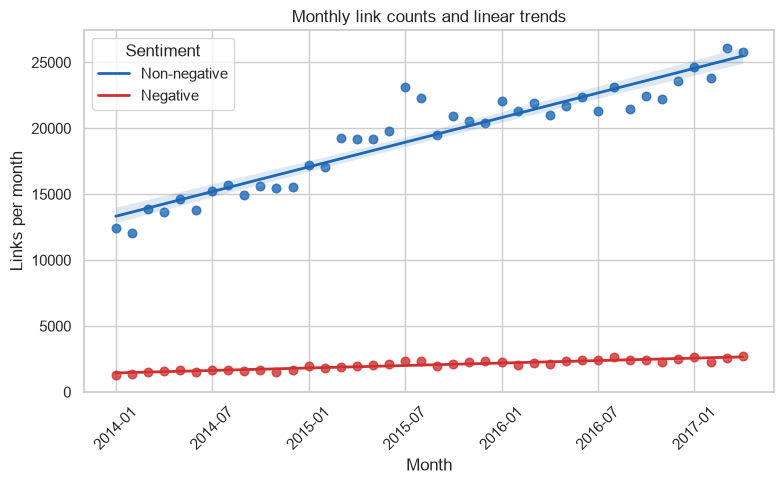

Non-negative: +1.70% per month
Negative: +1.60% per month
Negative share: -0.09% per month


,links,share
LINK_SENTIMENT,,
Non-negative,776278,90.42%
Negative,82210,9.58%


In [5]:
show_monthly_baseline(links)


The two count series grow at similar fitted monthly rates: 1.70% for non-negative links and 1.60% for negative links. The negative share changes by about -0.09% per month on this relative scale, so it remains close to one tenth of all links. This is a relative percent change in the share, not a change of 0.09 percentage points. Later response comparisons use rates within each selected-link group and state their denominators.

## 1. Origin: where does negativity first appear?

Before following how pairs evolve after a second link or how third communities react, we examine where negativity originates in an *observed* pair history. Specifically, we check how link sentiment varies by post location (`body` vs. `title`), how quickly a second interaction occurs, whether the first negative link between two communities happens on their very first recorded contact or after earlier non-negative links, and whether a directed negative link (`A → B`) is an unprovoked "first strike" or follows a prior negative link in the opposite direction (`B → A`). Finally, we explore location transitions and semantic similarity between subreddits.

### 1.1 Baseline sentiment by post location

In [6]:
stat = show_sentiment_by_location(links)

           count  positive_per  ci_lower  ci_upper
LOCATION                                          
body      286561      0.926473  0.925517  0.927429
title     571927      0.893098  0.892297  0.893899


Links embedded in the body of a post are non-negative 92.65% of the time (95% CI: 92.55%–92.74%), compared with 89.31% (95% CI: 89.23%–89.39%) for links placed in post titles. Put differently, title links have a higher negative share (~10.69%) than body links (~7.35%), suggesting that call-outs or critical references are more frequently highlighted in post titles.

### 1.2 Time interval between the first two links

To study pair histories without severe boundary truncation at the start and end of the dataset, we define `valid_pairs` by keeping pairs whose first observed link occurs at least 60 days after the start of the observation period and at least 60 days before the end. We then examine the time elapsed (in days) between the first (`position_in_pair == 0`) and second (`position_in_pair == 1`) recorded links in each pair, fitting an exponential distribution by initial sentiment and by initial post location.

In [7]:
links, valid_pairs = select_valid_origin_pairs(links, margin_days=60)

--- Exponential Fit Results: Positive Initial Sentiment ---
Lambda rate: 0.00607 per day
Mean response time (1/lambda): 164.84 days
Estimated median time: 114.26 days
Empirical median time (from data): 81.03 days



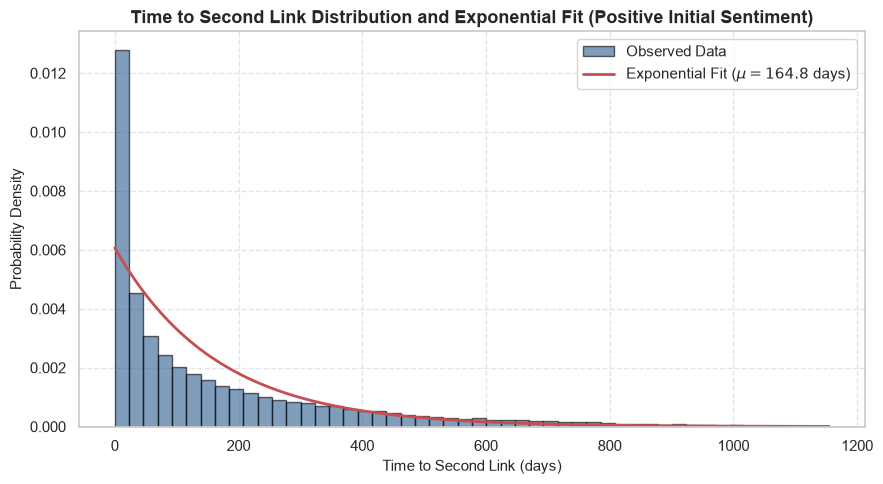

--- Exponential Fit Results: Negative Initial Sentiment ---
Lambda rate: 0.00610 per day
Mean response time (1/lambda): 163.90 days
Estimated median time: 113.61 days
Empirical median time (from data): 87.33 days



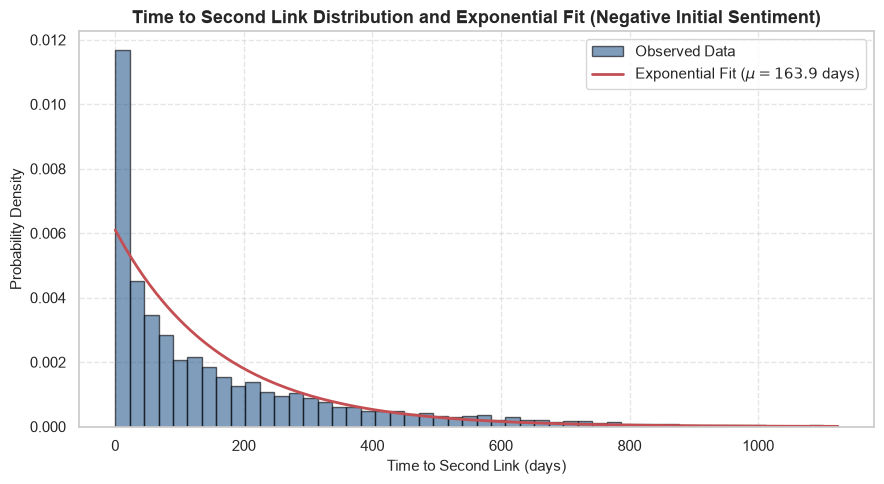

In [8]:
show_response_time_by_sentiment(valid_pairs)

--- Exponential Fit Results: First Link in Body ---
Lambda rate: 0.00632 per day
Mean response time (1/lambda): 158.11 days
Estimated median time: 109.59 days
Empirical median time (from data): 72.46 days



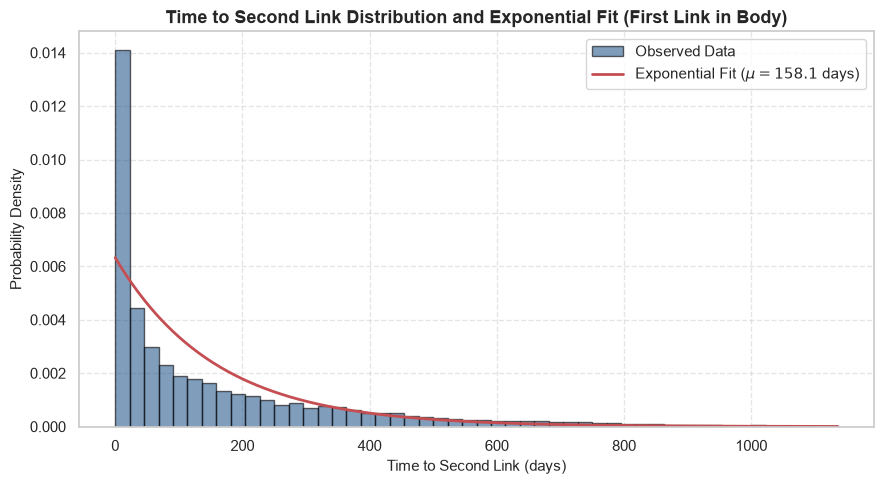

--- Exponential Fit Results: First Link in Title ---
Lambda rate: 0.00594 per day
Mean response time (1/lambda): 168.28 days
Estimated median time: 116.64 days
Empirical median time (from data): 86.19 days



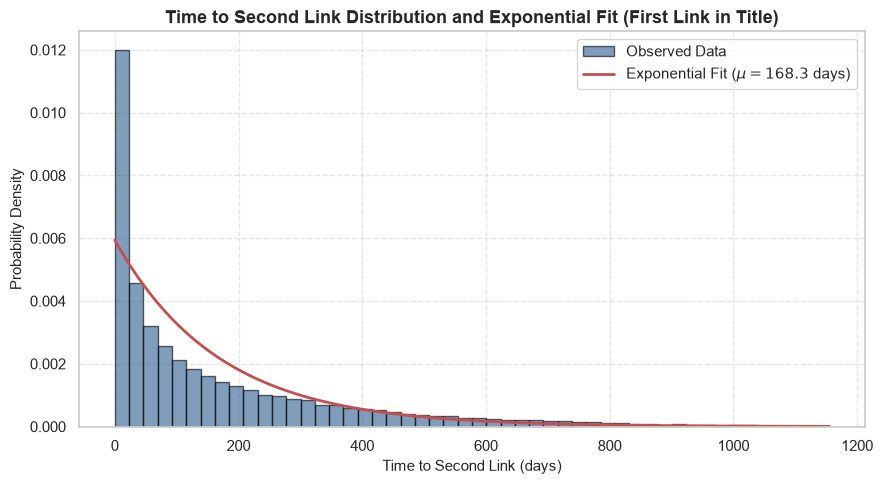

In [9]:
show_response_time_by_location(valid_pairs)

The time interval between the first and second observed links is strongly right-skewed: many second links occur within the first few days, while a long tail stretches over several months (the empirical median is around 81–87 days, well below the fitted exponential mean of ~164 days). Notably, the fitted mean time to a second link is virtually identical whether the first link is non-negative (164.84 days, empirical median 81.03 days) or negative (163.90 days, empirical median 87.33 days). When splitting by the location of the first link, pairs starting with a body link experience a slightly faster second interaction (mean 158.11 days, empirical median 72.46 days) than those starting with a title link (mean 168.28 days, empirical median 86.19 days).

### 1.3 Where negativity first appears in an observed pair history

Among all unordered pairs in `valid_pairs` that experience at least one negative link, we check whether the first negative interaction occurs on the very first recorded link (`position_in_pair == 0`, hostile first contact) or after one or more earlier non-negative links (`position_in_pair > 0`, delayed negativity).

In [10]:
first_neg_per_pair = show_negativity_origin_positions(valid_pairs)

Total pairs with at least one negative link: 33,282
First negative link at position > 0 (delayed negativity): 12,477
First negative link at position == 0 (hostile first contact): 20,805


Out of 33,282 unordered pairs with at least one recorded negative link, negativity appears on the very first observed link in 20,805 pairs (62.51%), whereas 12,477 pairs (37.49%) first interact non-negatively before any negative link is recorded. Thus, while a majority of negative pair histories begin with a negative first recorded contact, more than a third develop negativity only after prior non-negative interactions.

### 1.4 Directed origin: unprovoked first strike vs. retaliation

Because hyperlinks are directed (`A → B`), we also examine each directed pair's first negative link and check whether it follows an earlier negative link in the opposite direction (`B → A`). This distinguishes unprovoked initial negative links ("first strikes") from reciprocal negative responses ("retaliation").

In [11]:
merged_directed = show_directed_retaliation_origin(valid_pairs)

Total directed negative pairs (A -> B): 34,180
Follows an earlier negative link from B -> A (Retaliation): 898 (2.63%)
Does NOT follow an earlier negative link (First strike / Unprovoked): 33,282 (97.37%)


Across the 34,180 directed pairs `(A → B)` that ever record a negative link, 33,282 (97.37%) do *not* follow an earlier negative link from `B → A`—they represent the first negative strike between the two communities. Only 898 directed pairs (2.63%) have their first negative link `A → B` occur after a prior negative link from `B → A`. In other words, mutual negative escalation is rare: observed negativity between subreddits is overwhelmingly one-sided rather than reciprocal retaliation.

### 1.5 Post location transitions in reciprocal interactions

When the first two observed links in a pair are reciprocal (`A → B` followed by `B → A`), does the responding community mirror the post location (`body` vs. `title`) of the initial link, and does this depend on link sentiment?

In [12]:
first_two_recip = show_location_transitions(valid_pairs)


Transition table for the location:


second_location,body,title
first_location,,
body,62.51,37.49
title,34.71,65.29



Transition table for the location with negative first link:


second_location,body,title
first_location,,
body,53.12,46.88
title,34.47,65.53



Transition table for the location with positive first link:


second_location,body,title
first_location,,
body,62.93,37.07
title,34.72,65.28


In [13]:
show_location_transitions_by_sentiment_pair(first_two_recip)


CASE: negative_negative
Number of interactions: 98

Transition counts:
second_location  body  title
first_location              
body               19     16
title              22     41

Transition percentages:
second_location       body      title
first_location                       
body             54.285714  45.714286
title            34.920635  65.079365

CASE: positive_positive
Number of interactions: 14948

Transition counts:
second_location  body  title
first_location              
body             4553   2655
title            2673   5067

Transition percentages:
second_location       body      title
first_location                       
body             63.165927  36.834073
title            34.534884  65.465116

CASE: negative_positive
Number of interactions: 677

Transition counts:
second_location  body  title
first_location              
body              160    142
title             129    246

Transition percentages:
second_location       body      title
first_location 

Reciprocal interactions show strong location persistence: overall, 62.51% of responses to a `body` link are also placed in the `body`, and 65.29% of responses to a `title` link are also placed in the `title`. However, when the first link is negative (`negative_first_two`) or when negativity emerges on the second link (`positive_negative`), `body → title` transitions become noticeably more frequent (46.88% after a negative first link, and 42.96% in `positive_negative` pairs, compared with 36.83% in `positive_positive` pairs). Negative exchanges are thus more likely to shift into post titles.

### 1.6 Community similarity (subreddit embeddings) and link sentiment

Finally, we merge the SNAP subreddit embedding vectors (`web-redditEmbeddings-subreddits.csv`) with `valid_pairs` and compute the cosine similarity between the source and target subreddits. We compare the similarity distributions of negative and non-negative links and fit a logistic regression predicting non-negative sentiment (`LINK_SENTIMENT > 0`) from cosine similarity. From the graph, we can observe that the distribution of negative link sentiment is more left-skewed than that of non-negative sentiment. Furthermore, the distribution of cosine similarity for negative links is narrower and exhibits a higher density peak. This suggests that links between less similar subreddits are more likely to be associated with negative sentiment.

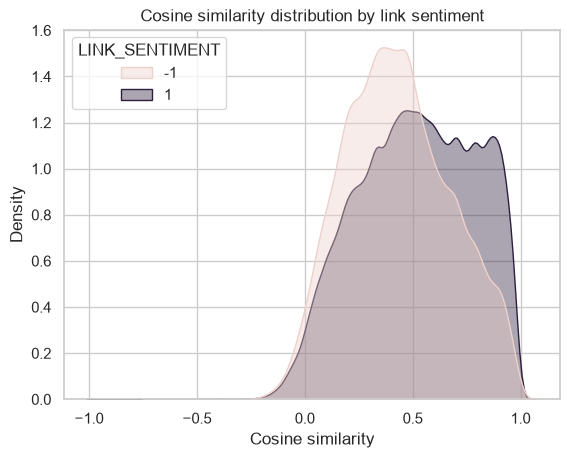

In [14]:
valid_pairs_emb = add_embedding_similarity(valid_pairs)
plot_similarity_by_sentiment(valid_pairs_emb)

In [15]:
sim_logit_res = fit_similarity_logit(valid_pairs_emb)

Optimization terminated successfully.
         Current function value: 0.300455
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                 binary   No. Observations:               544594
Model:                          Logit   Df Residuals:                   544592
Method:                           MLE   Df Model:                            1
Date:                Fri, 06 Nov 2026   Pseudo R-squ.:                 0.01488
Time:                        16:41:20   Log-Likelihood:            -1.6363e+05
converged:                       True   LL-Null:                   -1.6610e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             1.7140      0.009    188.599      0.000       1.696       1.732
cosine_s

The kernel density plot and logistic regression show a positive and statistically significant association between community similarity and non-negative sentiment ($\beta = 1.2394$, $p < 0.001$). Subreddits that are closer in embedding space are more likely to link to one another non-negatively, whereas negative links are shifted toward pairs of more dissimilar communities.

## 2. How do negative relationships evolve?

### 2.1 Select the second observed link in each pair

We use the full observation period. Each pair enters the analysis if its first recorded link is non-negative and it has a second recorded link with at least 30 days of data remaining. The second link is the selected event: it may be negative or non-negative. This gives both groups exactly one earlier interaction and one event per pair.

The first link may be in either direction. For a selected A → B link, `prior_reverse` means that the first link was B → A. We cannot know whether the dataset captured the pair’s first-ever interaction; pairs whose first recorded link is negative or that have only one recorded link are outside this analysis.

In [16]:
links, events, follow_up = select_second_links(links)


,pairs,same_direction_share,opposite_direction_share
group,,,
Negative,5946,87.17%,12.83%
Non-negative,75067,77.76%,22.24%


The first two observed links usually run in the same direction. This is especially true when the second link is negative: 87.17% repeat the first link’s direction, compared with 77.76% when the second link is non-negative. An early negative link is therefore more often a change in tone from the same source community than a negative link coming from the community that was linked to first.

### 2.2 Does the other community link back?

We search for the first link in the direction opposite to the selected second link, allowing same-direction links in between. We count a reverse link only if it arrives within 30 days.

In [17]:
links, events = measure_pair_responses(links, events, follow_up)


#### 2.2.1 Main comparison: the direction of the first link

The selected second link can repeat the first link’s direction or run in the opposite direction. These are different starting situations: a pair with opposite-direction links has already linked both ways. We compare response rates and the sentiment of first reverse links within each situation.

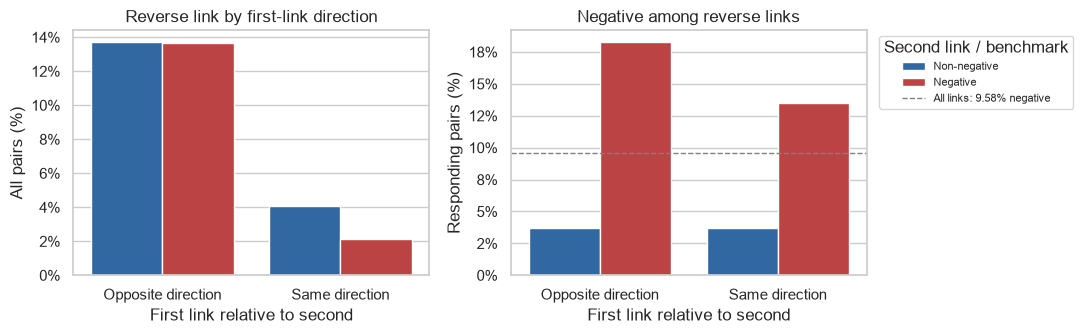

In [18]:
show_response_by_direction(events, links)


The pair’s first two directions are strongly associated with whether it links back again. If those links already ran in opposite directions, about 13.7% of pairs have a reverse link within 30 days, regardless of whether the second link was negative. If both links ran in the same direction, the rate is much lower: 2.14% after a negative second link and 4.06% after a non-negative one.

Sentiment shows a different pattern on the right. In both direction groups, the first reverse link is more often negative after a negative second link than after a non-negative one. The dashed line marks the 9.58% negative share across all links in the dataset: the negative-second-link bars lie above it, and the non-negative-second-link bars below it. This benchmark gives context, although all links are not a matched sample of reverse links.

#### 2.2.2 Overall rates across both direction groups

The pooled table summarizes all selected pairs, but it combines the two starting situations above. `another_link_rate` counts a later link in either direction within 30 days. `reverse_rate` counts only a link from the target back to the source. `negative_given_reverse` is the negative share of first reverse links among pairs that link back. The plot shows the last two rates with 95% Wilson intervals.

,another_link_rate,reverse_rate,negative_given_reverse
group,,,
Non-negative,23.12%,6.21%,3.69%
Negative,22.40%,3.62%,15.81%


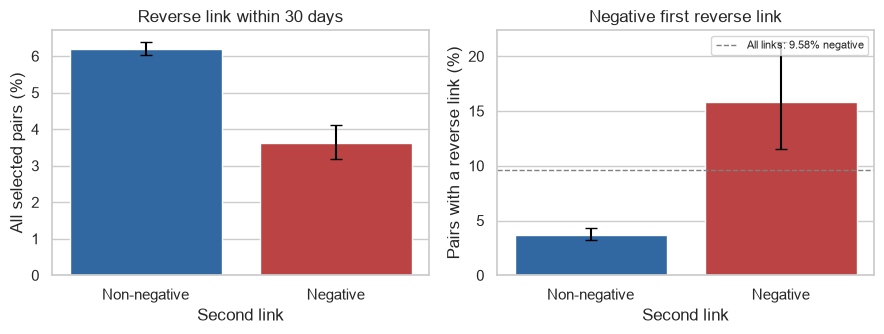

In [19]:
show_pooled_responses(events, links)


Across both direction groups, reverse links are less frequent after a negative second link (3.62% versus 6.21%). This pooled gap partly reflects that negative second links less often occur in pairs that have already linked both ways. Among pairs that do link back, a negative first reverse link is much more common after a negative second link (15.81% versus 3.69%). The dashed 9.58% line is the negative share of all dataset links: useful context, but not a matched reply comparison.

#### 2.2.3 Pooled time-window sensitivity

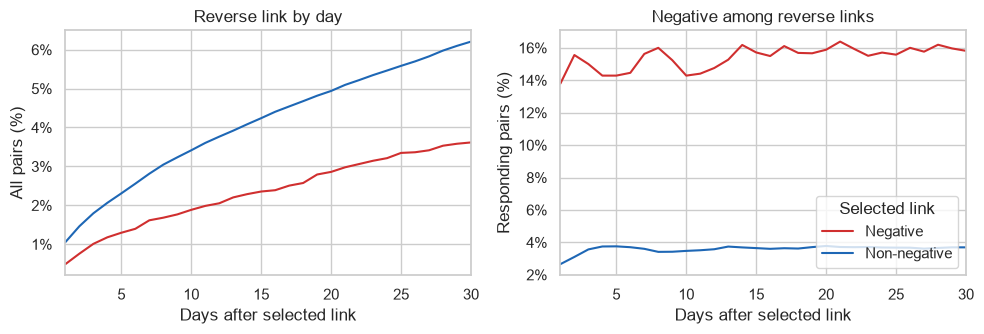

In [20]:
show_window_sensitivity(events)


The 30-day result is not specific to that cutoff. Across shorter and longer windows, non-negative second links are consistently followed by more reverse links than negative second links. Both curves on the left rise as the window grows: with more time, more pairs have a chance to produce a reverse link. On the right, the negative share among first reverse links changes relatively little with the window. It stays higher after a negative second link than after a non-negative one. These are pooled curves across the two first-link direction groups, which the main comparison separates.

#### 2.2.4 Adjustment for prior direction and calendar time

We model the reverse-link outcome with an interaction between second-link sentiment and prior direction, so the sentiment association may differ across the two starting situations. For negativity among responders, we use the same covariates without an interaction. Both models include year and title/body location, with standard errors clustered by target subreddit.

For the reverse-link outcome, the main terms are

$$\operatorname{logit}\bigl(P(Y_i=1)\bigr)=\beta_0+\beta_1\mathrm{NegativeLink}_i+\beta_2\mathrm{PriorReverse}_i+\beta_3(\mathrm{NegativeLink}_i\times\mathrm{PriorReverse}_i)+\gamma_{\mathrm{year}(i)}+\delta_{\mathrm{location}(i)}.$$

The conditional sentiment model omits the interaction. 

$$\operatorname{logit}\bigl(P(Y_i=1)\bigr)=\beta_0+\beta_1\mathrm{NegativeLink}_i+\beta_2\mathrm{PriorReverse}_i+\gamma_{\mathrm{year}(i)}+\delta_{\mathrm{location}(i)}.$$

Both describe associations, not causal effects.

In [21]:
events = fit_response_models(events)


,odds_ratio,ci_low,ci_high
outcome,,,
Reverse link: same direction,0.52,0.43,0.64
Reverse link: opposite direction,1.00,0.80,1.26
Negative if reversed,4.80,3.20,7.21


The regression supports the grouped comparisons after accounting for year and title/body location. When the first two links ran in the same direction, a negative second link is associated with about 48% lower odds of a reverse link within 30 days than a non-negative one (odds ratio 0.52, 95% CI 0.43–0.64). The entire interval is below 1, supporting a lower-odds association in this one-sided group. When the pair had already linked both ways, the odds ratio is 1.00 (95% CI 0.80–1.26). That interval includes 1, so we do not find a clear difference in reverse-link odds by second-link sentiment there.

Among pairs that link back, a negative second link is associated with 4.8 times the odds that the first reverse link is negative (odds ratio 4.80, 95% CI 3.20–7.21). This interval lies entirely above 1, supporting a higher-odds association. Odds are not probabilities, so these figures should be read alongside the observed percentages above. None of these associations establishes that the second link caused a response.

#### 2.2.5 One observed pair, as a timeline

The plot below is a concrete example of the sequence we measure. We select a pair with a negative first reverse link so both parts of the question are visible. It illustrates the definition; it is not selected as a representative pair.

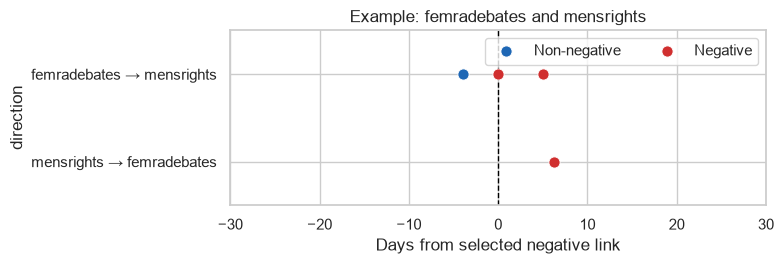

In [22]:
show_pair_timeline(events, links, follow_up)


## 3. Third-community attention

Having measured whether B links back to A, we now turn to other communities C. When A links negatively to B, do other communities begin linking to B more often, and are those links more negative? We call A → B a negative event. In this section, “attack” is only shorthand for the dataset's negative sentiment label; it does not establish the author's intention.

A is the source of the negative event, B its target, and C any other subreddit that links to B. For comparison, we match some targets B to a control subreddit B′ with similar earlier incoming-link activity. The matched comparison studies changes in attention; a separate, exploratory triangle analysis asks whether C had linked non-negatively with A before linking to B.


### 3.1 Negative events

For each target B, we take its first observed negative incoming link, A → B at time `t0`. We retain events from 1 January 2015 onward and require at least 30 days of later data. Earlier observed links are used as history; we cannot know whether this was B's first negative link before the dataset began. There is one event per B.


In [23]:
events, first_neg_time, n_attacked_ever, n_from_2015 = select_first_attacks(links)


6,635 attacked subreddits -> 4,197 first attacks from 2015 -> 4,000 with 30 days of follow-up


#### 3.1.1 Incoming links

Everything else is computed from one table with one row per link received by B, from a third community C (never from A), between 180 days before and 365 days after the attack.

| column | meaning |
|---|---|
| `event_id` | which attack (therefore which B) |
| `C` | the community that posted the link |
| `rel_day` | days since the attack (negative = before, positive = after) |
| `is_neg` | is the link negative? |

Once we have it, counting links in a window is just a `groupby`.

In [24]:
long = incoming_links(events, links)
print(f"{len(long):,} incoming links around the attacks (-180 days to +1 year)")
display(long.head())


70,943 incoming links around the attacks (-180 days to +1 year)


,event_id,C,rel_day,is_neg
0,1,gurbani,-171,False
1,1,punjabi,-148,False
2,1,gurbani,-128,False
3,1,gurbani,43,False
4,1,gurbani,43,False


#### 3.1.2 Time windows and counts

Windows use `[lo, hi)` in days relative to `t0`, with the upper bound excluded. The eligibility window is [-180, -90); it selects targets with at least four earlier incoming links from communities other than A. We compare [-30, 0) with [1, 31), leaving out day 0 so the event day is not mixed into the later period.

We select active targets using an earlier window than the one used for the before/after comparison. This reduces the mechanical decline that could appear if selection were based on an unusually busy period immediately before `t0`.


In [25]:
events = add_counts(events, long)
events["eligible"] = events.elig_n >= MIN_LINKS
print(f"{events.eligible.sum()} eligible events out of {len(events):,}")


455 eligible events out of 4,000


#### 3.1.3 How many negative events can we analyse?

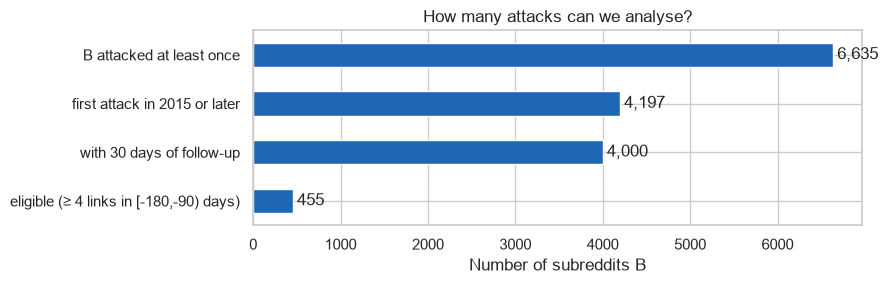

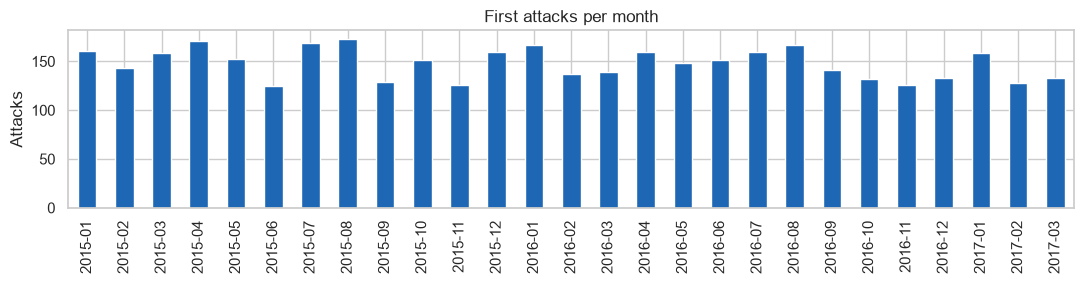

In [26]:
show_attack_funnel(events, n_attacked_ever, n_from_2015)


Of the 4,000 first observed negative events with follow-up, 455 meet the earlier-activity threshold. First events are spread across the period without an obvious single monthly spike. The matched analysis below uses the 449 events for which a suitable control was found.


### 3.2 Matched controls

A target might receive more links after `t0` because of wider Reddit activity or its own growth. We therefore match each eligible B to a control B′ at the same date. A candidate must have at least four incoming links in [-180, -90), have no observed negative incoming link before `t0`, and resemble B's incoming-link counts in both [-180, -90) and [-90, 0). Matching uses the distance between `log1p` counts; a control may be used for more than one event.

This comparison adjusts for those observed activity patterns, but it cannot isolate a causal effect of the negative link.


In [27]:
controls = match_controls(events, links, first_neg_time)


449 / 455 events matched | 334 distinct controls


The control B′ receives the same event date `t0` and source A as its matched B. Links from A are excluded from both targets' third-community counts.


In [28]:
# One row per matched event, with B' in column B.
controls = controls.merge(events[["event_id", "A", "t0"]], on="event_id").rename(columns={"control": "B"})

# Controls attacked within 30 days of t0 are kept (dropping them would bias the negative share down by construction).
controls["attacked_post30"] = first_neg_time.reindex(controls.B).to_numpy() < (controls.t0 + 31 * DAY).to_numpy()
print(f"{controls.attacked_post30.mean():.1%} of controls are attacked within 30 days")

ctrl_long = incoming_links(controls, links)      # same function, same table format as for the events
controls = add_counts(controls, ctrl_long)
assert (controls.elig_n >= MIN_LINKS).all()

# Aligned tables: same events, same order, for attacked B (ev_m) and control B' (ct_m).
ids = controls.event_id.to_numpy()
ev_m = events.set_index("event_id").loc[ids]
ct_m = controls.set_index("event_id").loc[ids]

3.1% of controls are attacked within 30 days


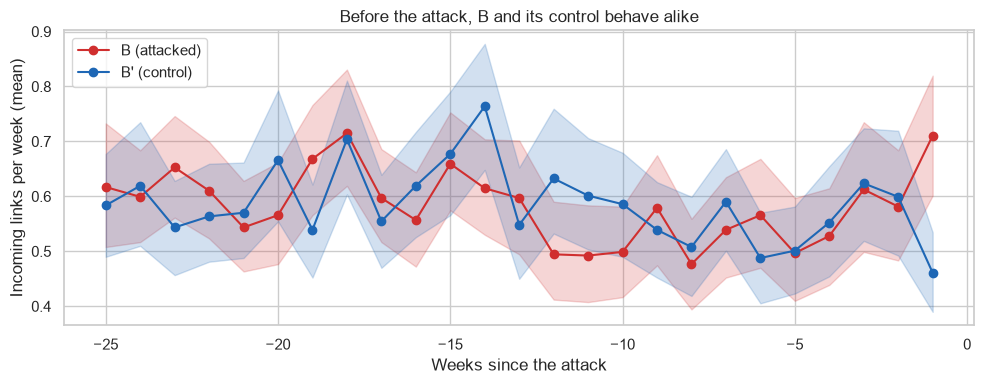

In [29]:
plot_weekly(ids, range(-25, 0), "Before the attack, B and its control behave alike",
            long, ctrl_long)


Before `t0`, the matched targets and controls have similar average weekly incoming-link patterns. Their curves separate around week 0. This supports the activity match, but it does not rule out an event or trend affecting B and B′ differently after that date.


### 3.3 The spotlight

Question. After the attack, do other communities link to B more than they link to a similar subreddit that was not attacked? And are those links hostile?

#### 3.3.1 Weekly attention around the event

For the 13-week plot, we keep only matched events with at least 91 days of later coverage. Otherwise, events near the dataset's end would make the later weeks look artificially quiet.


429 matched events with 91 days of follow-up


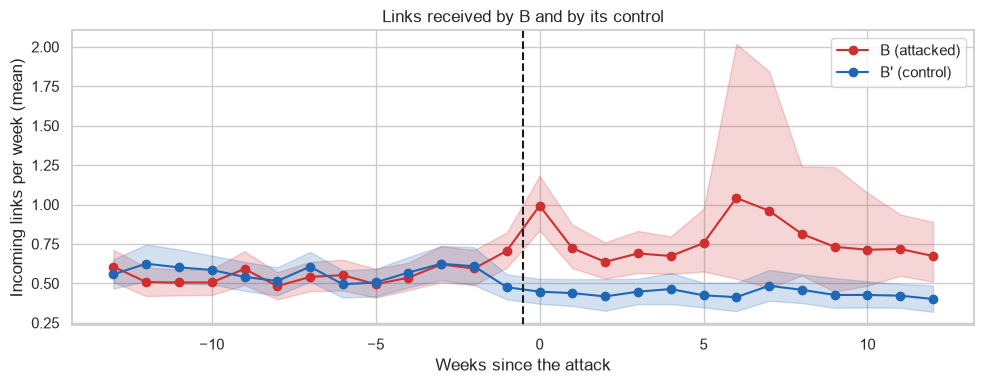

In [30]:
full_91 = ev_m.t0 + 91 * DAY <= links.time.max()
curve_ids = ids[full_91.to_numpy()]
print(f"{len(curve_ids)} matched events with 91 days of follow-up")

plot_weekly(curve_ids, range(-13, 13), "Links received by B and by its control", long, ctrl_long, attack_line=True)

The average for B rises sharply around weeks 5–7. Because this is an unnormalized mean, one unusually active target could drive the peak. We identify the largest contributors and then redraw the curve without the leading outlier.


In [31]:
# The events that contribute most to the links received in weeks 5 to 7.
tab = weekly_table(long, curve_ids, range(-13, 13))
top = tab[[5, 6, 7]].sum(axis=1).sort_values(ascending=False).head(5)
display(events.set_index("event_id").loc[top.index, ["A", "B", "t0"]].assign(links_weeks_5_to_7=top))
print(f"Pokemongo = {top.iloc[0] / tab[[5, 6, 7]].to_numpy().sum():.0%} of all links in weeks 5-7")

,A,B,t0,links_weeks_5_to_7
event_id,,,,
2545,pokemongoblue,pokemongo,2016-05-26 18:24:11,386
3099,shitstatistssay,garyjohnson,2016-09-12 00:35:33,28
1965,hoverjunkers,vive,2016-01-28 14:55:01,20
1861,jezopolis,whowouldwinverse,2016-01-09 13:59:14,15
928,bipolar,mneumonese,2015-07-05 00:48:16,14


Pokemongo = 33% of all links in weeks 5-7


Indeed, this subreddit called pokemongo received 33% of all links received in weeks 5–7 after the attack.

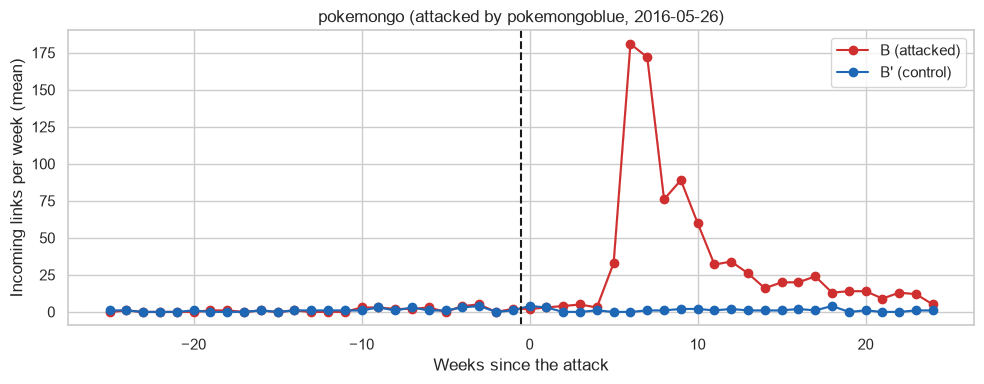

In [32]:
plot_weekly([2545], range(-25, 25), title="pokemongo (attacked by pokemongoblue, 2016-05-26)", long=long, ctrl_long=ctrl_long, attack_line=True)

The Pokémon GO example illustrates why the large peak should not be attributed to the negative link alone: a target can receive substantial attention for reasons outside this network event. We use it to check the sensitivity of the weekly average, while retaining the event in the other analyses.


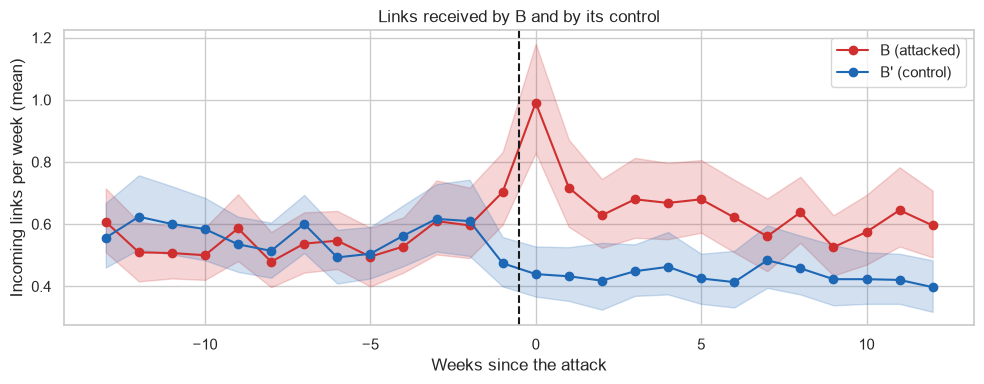

In [33]:
# Remove the Pokémon GO event from this curve only; keep it in the event sample.
curve_ids = curve_ids[curve_ids != 2545]
plot_weekly(curve_ids, range(-13, 13), "Links received by B and by its control", long, ctrl_long, attack_line=True)

This seems to confirm that this subreddit was driving this effect on its own.

#### 3.3.2 How much more? A ratio of ratios

We compare each group's total incoming links in the 30 days after `t0` with its total in the 30 days before, excluding day 0. Dividing B's after/before ratio by B′'s gives a ratio of ratios: 1 means equal proportional change. The 95% interval resamples matched events with replacement and recomputes all ratios.


In [34]:
ratios = boot_ratios(ev_m, ct_m)
display(ratios.round(2))


,estimate,low,high
B: after / before,1.21,1.07,1.36
B': after / before,0.78,0.68,0.88
B / B' (ratio of ratios),1.56,1.34,1.83


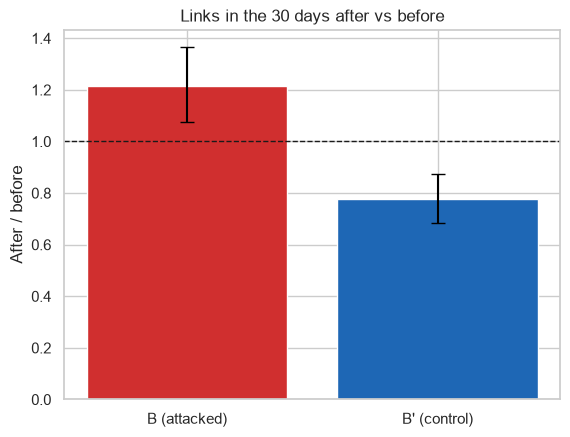

In [35]:
# Left: after / before, for B and for its control (1 = no change)
plot_ratio_bars(ratios)

Across the 449 matched events, incoming links to B rise by a factor of 1.21 after versus before `t0`, while links to B′ fall to 0.78 of their earlier total. The ratio of ratios is 1.56 (95% bootstrap interval 1.34–1.83). This shows a larger relative increase for B in the matched comparison; it does not establish that the negative link caused the difference.


#### 3.3.3 Is the attention more negative?

We compare the share of negative links after the attack, B against B′.

,share,low,high
B (attacked),0.042,0.030,0.055
B' (control),0.019,0.009,0.031


,difference,low,high,p_value
B minus B',0.022,0.005,0.039,0.009


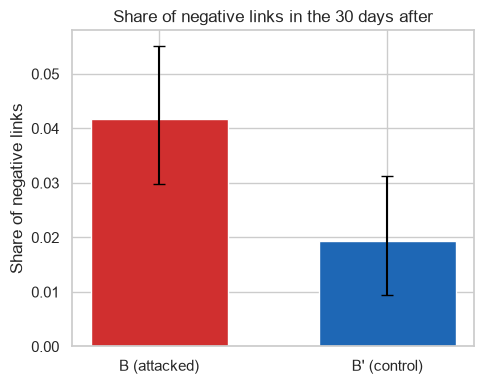

In [36]:
show_negative_share_comparison(ev_m, ct_m)

In the 30 days after the negative event, 4.2% of third-community links to B are negative, versus 1.9% for matched controls. The difference is 2.2 percentage points (95% bootstrap interval 0.5–3.9 points). Negative attention is higher for B in this comparison, but most incoming links to both groups are non-negative. The full dataset's 9.58% negative share is context, not a matched benchmark for these selected targets.


### 3.4 Prior ties and third-party negativity

The matched analysis measures attention to B. We now ask a different, exploratory question: among third communities C that link to B after the negative event, are those with a prior non-negative link to A more likely to link negatively to B? This uses all 4,000 dated events with complete 30-day follow-up, rather than only the 449 matched events. The comparison is descriptive; prior links to A do not establish friendship or coordination.


#### 3.4.1 Detecting temporal triangles

For each A → B negative event at `t0`, we identify C → B links in the next 30 days. We mark C as previously connected to A if at least one non-negative link ran between A and C, in either direction, during the preceding 90 days. We also record whether C had linked to B in that earlier period.

A negative temporal triangle consists of a prior non-negative A–C link, the A → B negative event, and a later negative C → B link. Here a non-negative link means `LINK_SENTIMENT = +1`, including neutral and positive labels. One prior link is enough for this descriptive classification; it does not imply an alliance. The 90-day and 30-day windows are analysis choices.


In [37]:
links_by_target, links_by_source = make_link_lookups(links)


In [38]:
all_third_party_links = run_triangles(events, links_by_target, links_by_source)      # attacked B
ctrl_third_party_links = run_triangles(controls, links_by_target, links_by_source)   # control B'

# Add our event_id, so that these tables connect with `events`, `controls` and the bootstrap helpers.
n_rows = len(all_third_party_links), len(ctrl_third_party_links)
all_third_party_links = all_third_party_links.merge(events[["A", "B", "t0", "event_id"]], on=["A", "B", "t0"])
ctrl_third_party_links = ctrl_third_party_links.merge(controls[["A", "B", "t0", "event_id"]], on=["A", "B", "t0"])
assert (len(all_third_party_links), len(ctrl_third_party_links)) == n_rows      # the merge neither lost nor duplicated rows

display(all_third_party_links.head())

,SOURCE_SUBREDDIT,TARGET_SUBREDDIT,POST_ID,LINK_SENTIMENT,LOCATION,time,pair_a,pair_b,position_in_pair,first_sentiment,...,first_time,next_pair_time,A,B,C,t0,positive_AC,previous_CB,negative_CB,event_id
0,deadmalls,urbanexploration,2vgc54s,1,title,2015-01-06 08:45:35,deadmalls,urbanexploration,0,1,...,2015-01-06 08:45:35,NaT,saltlakecity,urbanexploration,deadmalls,2015-01-03 18:27:09,False,False,False,7
1,writingprompts,urbanexploration,2ryewds,1,body,2015-01-10 03:20:25,urbanexploration,writingprompts,2,1,...,2014-02-03 00:52:14,NaT,saltlakecity,urbanexploration,writingprompts,2015-01-03 18:27:09,False,False,False,7
2,hiphopheads,deathgrips,2rdwpns,1,title,2015-01-05 00:48:07,deathgrips,hiphopheads,0,1,...,2015-01-05 00:48:07,NaT,bestof,deathgrips,hiphopheads,2015-01-04 22:17:19,True,False,False,10
3,outoftheloop,deathgrips,2rf5u6s,1,body,2015-01-05 09:57:18,deathgrips,outoftheloop,0,1,...,2015-01-05 09:57:18,NaT,bestof,deathgrips,outoftheloop,2015-01-04 22:17:19,True,False,False,10
4,pixelsorting,deathgrips,2scdw7s,1,title,2015-01-15 12:15:54,deathgrips,pixelsorting,0,1,...,2015-01-15 12:15:54,NaT,bestof,deathgrips,pixelsorting,2015-01-04 22:17:19,False,False,False,10


#### 3.4.2 Counting negative temporal triangles

We count each distinct (A, B, `t0`, C) combination once when C had a prior non-negative tie to A and later linked negatively to B. Multiple C → B links from the same C after one event do not create multiple triangles. The table and plot below additionally compare the negative share of all post-event C → B links by whether C had that prior tie.


In [39]:
# Triangles where C had a positive tie with A
positive_triangles = all_third_party_links[
    all_third_party_links["positive_AC"]
].copy()

# Triangles where C negatively links to B after A's attack
negative_triangles = positive_triangles[
    positive_triangles["negative_CB"]
].copy()

# Count distinct triangles
n_triangles = (
    negative_triangles[["A", "B", "t0", "C"]]
    .drop_duplicates()
    .shape[0]
)

print("Number of negative triangles:", n_triangles)

Number of negative triangles: 253


In [40]:
summary = all_third_party_links.groupby("positive_AC").agg(
    n_links=("negative_CB", "size"),
    negative_share=("negative_CB", "mean")
)

display(summary)
summary.index

,n_links,negative_share
positive_AC,,
False,5155,0.093113
True,1777,0.154755


Index([False, True], dtype='bool', name='positive_AC')

Text(0, 0.5, 'Share of negative C → B links')

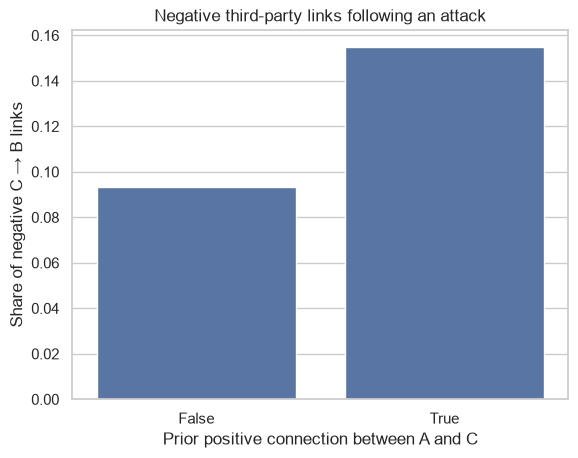

In [41]:
ax = sns.barplot(x=summary.index, y="negative_share", data=summary)
ax.set_title(
    "Negative third-party links following an attack"
)
ax.set_xlabel("Prior positive connection between A and C")
ax.set_ylabel("Share of negative C → B links")

Among post-event C → B links, 15.48% are negative when C had a prior non-negative link with A, compared with 9.31% when it did not. We also observe 253 distinct negative temporal triangles. These are link-level shares across all dated events, not the matched target-control comparison above. The difference may reflect which communities already interact with A or B; it cannot by itself show that negativity spread from A to C.

## 4. Synthesis and limits

Across the full pair history, negativity most often appears on the first recorded contact (62.5%) rather than after prior non-negative links, and directed negative links are overwhelmingly one-sided first strikes (97.4%) rather than reciprocal retaliation (Section 1). Within pairs that start with a non-negative link (Section 2), prior direction matters for whether a reverse link appears, while a negative second link is associated with a more negative first reverse link when one does appear. Beyond the pair, targets receive more third-community attention than matched controls after their first observed negative incoming link, and prior ties to the source are associated with a higher negative share among later third-party links. Together, these results describe different scales of the same network: the A–B relationship and the communities around it.

All results are observational. The dataset begins after Reddit's launch, sentiment labels can misclassify tone, the matched controls need not share every relevant trend, and the triangle comparison does not establish coordination or contagion.
